In [1]:
import pandas as pd
import numpy as np
import os

data_path = "data/raw/"

counts = pd.read_csv(
    data_path + "GSE311770_all_samples_rsem_gene_counts.tsv.gz",
    sep="\t",
    compression="gzip"
)

print("Dataset dimensions:", counts.shape)

display(counts.head())

Dataset dimensions: (63140, 106)


,gene_id,1_VP_001_perilesioneel_huid_A12,1_VP_008_01_X_lesioneel_huid_A1,2_VP_001_gezond_huid_B12,2_VP_008_01_X_perilesioneel_huid_B1,3_VP_002_01_lesioneel__C12,3_VP_008_01_X_gezond_huid_C1,4_VP_002_01_perilesioneel__D12,4_VP_017_01_lesioneel_D1,5_VP_002_01_gezond_E12,...,48_Control_22_H6,49_Control_6__A6,49_Control_23_A7,50_Control_7__B6,50_Control_24_B7,51_Control_8__C6,51_Control_25_C7,52_Control_9__D6,52_Control_26_D7,53_Control_27_E7
0,ENSG00000000003,109,89,13,26,7,23,11,12,1,...,63,19,113,14,68,59,57,30,203,329
1,ENSG00000000005,50,7,1,1,0,11,0,0,3,...,15,9,12,0,24,2,8,9,10,28
2,ENSG00000000419,197,193,25,127,50,103,21,69,51,...,176,70,188,47,189,101,192,62,192,336
3,ENSG00000000457,90,62,26,92,28,54,12,28,6,...,54,37,108,15,117,52,83,48,48,73
4,ENSG00000000460,14,14,5,16,5,10,2,6,5,...,4,0,13,4,21,12,18,9,10,42


In [2]:
print(counts.info())
print(counts.columns.tolist()[:10])

<class 'pandas.DataFrame'>
RangeIndex: 63140 entries, 0 to 63139
Columns: 106 entries, gene_id to 53_Control_27_E7
dtypes: int64(105), str(1)
memory usage: 51.1 MB
None
['gene_id', '1_VP_001_perilesioneel_huid_A12', '1_VP_008_01_X_lesioneel_huid_A1', '2_VP_001_gezond_huid_B12', '2_VP_008_01_X_perilesioneel_huid_B1', '3_VP_002_01_lesioneel__C12', '3_VP_008_01_X_gezond_huid_C1', '4_VP_002_01_perilesioneel__D12', '4_VP_017_01_lesioneel_D1', '5_VP_002_01_gezond_E12']


In [3]:
# Extract all sample names
sample_names = counts.columns.drop("gene_id")

print("Total samples:", len(sample_names))

for sample in sample_names:
    print(sample)

Total samples: 105
1_VP_001_perilesioneel_huid_A12
1_VP_008_01_X_lesioneel_huid_A1
2_VP_001_gezond_huid_B12
2_VP_008_01_X_perilesioneel_huid_B1
3_VP_002_01_lesioneel__C12
3_VP_008_01_X_gezond_huid_C1
4_VP_002_01_perilesioneel__D12
4_VP_017_01_lesioneel_D1
5_VP_002_01_gezond_E12
5_VP_017_01_perilesioneel_E1
6_VP_003_01_lesioneel_F12
6_VP_017_01_gezond_F1
7_VP_003_01_perilesioneel_G12
7_VP_020_01_X_lesioneel_G1
8_VP_003_01_gezond_H12
8_VP_020_01_X_perilesioneel_H1
9_VP_004_01_lesioneel_A11
9_VP_020_01_X_gezond_A2
10_VP_004_01_perilesioneel_B11
10_controle_10_B2
11_VP_004_01_gezond_C11
11_controle_11_C2
12_VP_005_01_lesioneel_D11
12_controle_12_D2
13_VP_005_01_perilesioneel_E11
13_VP_008_01_perilesioneel_huid_E2
14_VP_005_01_gezond_F11
14_VP_008_01_gezond_F2
15_VP_006_01_lesioneel_G11
15_VP_021_01_lesioneel_G2
16_VP_006_01_perilesioneel_H11
16_VP_021_01_perilesioneel_H2
17_VP_006_01_gezond_A10
17_VP_021_01_gezond_A3
18_VP_007_01_lesioneel_B10
18_VP_024_01_lesioneel_huid_B3
19_VP_007_01_pe

In [4]:
# Check gene identifiers
print("Unique gene IDs:", counts["gene_id"].nunique())

print("Duplicate gene IDs:", counts["gene_id"].duplicated().sum())

print("Missing values:", counts.isnull().sum().sum())

Unique gene IDs: 63140
Duplicate gene IDs: 0
Missing values: 0


In [5]:
# Check expression count distribution
expression_data = counts.drop(columns="gene_id")

print(expression_data.describe())

       1_VP_001_perilesioneel_huid_A12  1_VP_008_01_X_lesioneel_huid_A1  \
count                     63140.000000                     63140.000000   
mean                         71.884685                        79.709075   
std                        1628.365579                      1761.564155   
min                           0.000000                         0.000000   
25%                           0.000000                         0.000000   
50%                           0.000000                         0.000000   
75%                           7.000000                         7.000000   
max                      385118.000000                    414121.000000   

       2_VP_001_gezond_huid_B12  2_VP_008_01_X_perilesioneel_huid_B1  \
count              63140.000000                         63140.000000   
mean                  32.755084                            62.361657   
std                 1175.773577                          1747.254551   
min                    0.000000     

In [6]:
# Classify samples using their names

for sample in sample_names:

    if "perilesioneel" in sample:
        group = "Perilesional"

    elif "lesioneel" in sample:
        group = "Lesional"

    elif "gezond" in sample:
        group = "Healthy"

    else:
        group = "Unknown"

    print(sample, ":", group)
    

1_VP_001_perilesioneel_huid_A12 : Perilesional
1_VP_008_01_X_lesioneel_huid_A1 : Lesional
2_VP_001_gezond_huid_B12 : Healthy
2_VP_008_01_X_perilesioneel_huid_B1 : Perilesional
3_VP_002_01_lesioneel__C12 : Lesional
3_VP_008_01_X_gezond_huid_C1 : Healthy
4_VP_002_01_perilesioneel__D12 : Perilesional
4_VP_017_01_lesioneel_D1 : Lesional
5_VP_002_01_gezond_E12 : Healthy
5_VP_017_01_perilesioneel_E1 : Perilesional
6_VP_003_01_lesioneel_F12 : Lesional
6_VP_017_01_gezond_F1 : Healthy
7_VP_003_01_perilesioneel_G12 : Perilesional
7_VP_020_01_X_lesioneel_G1 : Lesional
8_VP_003_01_gezond_H12 : Healthy
8_VP_020_01_X_perilesioneel_H1 : Perilesional
9_VP_004_01_lesioneel_A11 : Lesional
9_VP_020_01_X_gezond_A2 : Healthy
10_VP_004_01_perilesioneel_B11 : Perilesional
10_controle_10_B2 : Unknown
11_VP_004_01_gezond_C11 : Healthy
11_controle_11_C2 : Unknown
12_VP_005_01_lesioneel_D11 : Lesional
12_controle_12_D2 : Unknown
13_VP_005_01_perilesioneel_E11 : Perilesional
13_VP_008_01_perilesioneel_huid_E2 : P

In [7]:
# Dataset quality summary

print("DATASET SUMMARY")
print("------------------------")

print("Total genes:", counts.shape[0])
print("Total samples:", len(sample_names))

print("Unique gene IDs:", counts["gene_id"].nunique())
print("Duplicate gene IDs:", counts["gene_id"].duplicated().sum())

print("Missing values:", counts.isnull().sum().sum())

print("\nSAMPLE CATEGORIES")

for category in ["perilesioneel", "lesioneel", "gezond"]:
    total = sum(category in s.lower() for s in sample_names)
    print(category, ":", total)

print("\nEXPRESSION SUMMARY")
display(expression_data.describe().round(2))

DATASET SUMMARY
------------------------
Total genes: 63140
Total samples: 105
Unique gene IDs: 63140
Duplicate gene IDs: 0
Missing values: 0

SAMPLE CATEGORIES
perilesioneel : 27
lesioneel : 51
gezond : 28

EXPRESSION SUMMARY


,1_VP_001_perilesioneel_huid_A12,1_VP_008_01_X_lesioneel_huid_A1,2_VP_001_gezond_huid_B12,2_VP_008_01_X_perilesioneel_huid_B1,3_VP_002_01_lesioneel__C12,3_VP_008_01_X_gezond_huid_C1,4_VP_002_01_perilesioneel__D12,4_VP_017_01_lesioneel_D1,5_VP_002_01_gezond_E12,5_VP_017_01_perilesioneel_E1,...,48_Control_22_H6,49_Control_6__A6,49_Control_23_A7,50_Control_7__B6,50_Control_24_B7,51_Control_8__C6,51_Control_25_C7,52_Control_9__D6,52_Control_26_D7,53_Control_27_E7
count,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,...,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00,63140.00
mean,71.88,79.71,32.76,62.36,30.60,49.92,25.45,37.30,24.69,83.56,...,75.26,42.15,84.86,28.08,76.44,53.03,75.84,44.43,71.20,99.59
std,1628.37,1761.56,1175.77,1747.25,1087.95,1586.71,999.29,1279.67,819.30,2096.70,...,1455.53,1180.08,1235.04,915.81,1194.33,1228.53,1256.03,1052.44,1196.82,1759.96
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7.00,7.00,2.00,5.00,2.00,4.00,2.00,2.00,2.00,6.00,...,7.00,3.00,7.00,2.00,7.00,4.00,7.00,3.00,6.00,9.00
max,385118.00,414121.00,286941.00,419914.00,264444.00,387819.00,244686.00,311340.00,198656.00,497032.00,...,337499.00,285675.00,262224.00,222615.00,265773.00,291235.00,282214.00,248377.00,269047.00,398816.00


In [8]:
print(sample_names[:5].tolist())
print("...")
print(sample_names[-5:].tolist())

['1_VP_001_perilesioneel_huid_A12', '1_VP_008_01_X_lesioneel_huid_A1', '2_VP_001_gezond_huid_B12', '2_VP_008_01_X_perilesioneel_huid_B1', '3_VP_002_01_lesioneel__C12']
...
['51_Control_8__C6', '51_Control_25_C7', '52_Control_9__D6', '52_Control_26_D7', '53_Control_27_E7']


In [9]:
def classify_sample(sample):
    name = sample.lower()

    if "perilesioneel" in name:
        return "Perilesional"

    elif "lesioneel" in name:
        return "Lesional"

    elif "gezond" in name:
        return "Non-lesional"

    elif "control" in name:
        return "Healthy control"

    else:
        return "Unknown"


sample_metadata = pd.DataFrame({
    "sample": sample_names,
    "group": [classify_sample(s) for s in sample_names]
})

print(sample_metadata["group"].value_counts())

print("\nUnknown samples:")
display(sample_metadata[sample_metadata["group"] == "Unknown"])

print("\nTotal classified:", len(sample_metadata))

group
Non-lesional       28
Perilesional       27
Healthy control    26
Lesional           24
Name: count, dtype: int64

Unknown samples:


,sample,group



Total classified: 105


In [10]:
display(
    sample_metadata[
        sample_metadata["group"] == "Non-lesional"
    ].to_string(index=False)
)

'                      sample        group\n    2_VP_001_gezond_huid_B12 Non-lesional\n3_VP_008_01_X_gezond_huid_C1 Non-lesional\n      5_VP_002_01_gezond_E12 Non-lesional\n       6_VP_017_01_gezond_F1 Non-lesional\n      8_VP_003_01_gezond_H12 Non-lesional\n     9_VP_020_01_X_gezond_A2 Non-lesional\n     11_VP_004_01_gezond_C11 Non-lesional\n     14_VP_005_01_gezond_F11 Non-lesional\n      14_VP_008_01_gezond_F2 Non-lesional\n     17_VP_006_01_gezond_A10 Non-lesional\n      17_VP_021_01_gezond_A3 Non-lesional\n    20_VP_007_01_gezond__D10 Non-lesional\n 20_VP_024_01_gezond_huid_D3 Non-lesional\n    23_Controle_15_gezond_G3 Non-lesional\n     23_VP_009_01_gezond_G10 Non-lesional\n      26_VP_010_01_gezond_B9 Non-lesional\n      26_VP_015_01_gezond_B4 Non-lesional\n      29_VP_011_01_gezond_E9 Non-lesional\n      29_VP_022_01_gezond_E4 Non-lesional\n      32_VP_012_01_gezond_H9 Non-lesional\n      32_VP_026_01_gezond_H4 Non-lesional\n      35_VP_014_01_gezond_C8 Non-lesional\n      38_V

In [11]:
display(
    sample_metadata[
        sample_metadata["group"] == "Healthy control"
    ].to_string(index=False)
)

'           sample           group\n10_controle_10_B2 Healthy control\n11_controle_11_C2 Healthy control\n12_controle_12_D2 Healthy control\n21_Controle_13_E3 Healthy control\n22_Controle_14_F3 Healthy control\n 33_Control_16_A5 Healthy control\n 34_Control_17_B5 Healthy control\n 35_Control_18_C5 Healthy control\n 44_Control_1__D7 Healthy control\n 45_Control_2__E7 Healthy control\n 45_Control_19_E6 Healthy control\n  46_Control_3_F7 Healthy control\n 46_Control_20_F6 Healthy control\n 47_Control_4__G7 Healthy control\n 47_Control_21_G6 Healthy control\n 48_Control_5__H7 Healthy control\n 48_Control_22_H6 Healthy control\n 49_Control_6__A6 Healthy control\n 49_Control_23_A7 Healthy control\n 50_Control_7__B6 Healthy control\n 50_Control_24_B7 Healthy control\n 51_Control_8__C6 Healthy control\n 51_Control_25_C7 Healthy control\n 52_Control_9__D6 Healthy control\n 52_Control_26_D7 Healthy control\n 53_Control_27_E7 Healthy control'

In [12]:
for group in sample_metadata["group"].unique():
    print(f"\n{group}:")
    print(
        sample_metadata.loc[
            sample_metadata["group"] == group,
            "sample"
        ].head(3).tolist()
    )


Perilesional:
['1_VP_001_perilesioneel_huid_A12', '2_VP_008_01_X_perilesioneel_huid_B1', '4_VP_002_01_perilesioneel__D12']

Lesional:
['1_VP_008_01_X_lesioneel_huid_A1', '3_VP_002_01_lesioneel__C12', '4_VP_017_01_lesioneel_D1']

Non-lesional:
['2_VP_001_gezond_huid_B12', '3_VP_008_01_X_gezond_huid_C1', '5_VP_002_01_gezond_E12']

Healthy control:
['10_controle_10_B2', '11_controle_11_C2', '12_controle_12_D2']


In [13]:
# Clean English sample group summary

group_names = {
    "Lesional": "Lesional skin",
    "Perilesional": "Perilesional skin",
    "Non-lesional": "Non-lesional skin",
    "Healthy control": "Healthy control skin"
}

summary = (
    sample_metadata["group"]
    .value_counts()
    .rename(index=group_names)
    .rename_axis("Sample group")
    .reset_index(name="Number of samples")
)

display(summary)

,Sample group,Number of samples
0,Non-lesional skin,28
1,Perilesional skin,27
2,Healthy control skin,26
3,Lesional skin,24


In [14]:
import os

files = os.listdir("data/raw")

for file in files:
    print(file)

GSE311770_series_matrix.txt.gz
GSE311770_all_samples_rsem_gene_counts.tsv.gz


In [9]:
def classify_sample(sample):
    name = sample.lower()

    if "perilesioneel" in name:
        return "Perilesional"

    elif "lesioneel" in name:
        return "Lesional"

    elif "gezond" in name:
        return "Non-lesional"

    elif "control" in name:
        return "Healthy control"

    else:
        return "Unknown"


sample_metadata = pd.DataFrame({
    "sample": sample_names,
    "group": [classify_sample(s) for s in sample_names]
})

print(sample_metadata["group"].value_counts())

print("\nUnknown samples:")
display(sample_metadata[sample_metadata["group"] == "Unknown"])

print("\nTotal classified:", len(sample_metadata))

group
Non-lesional       28
Perilesional       27
Healthy control    26
Lesional           24
Name: count, dtype: int64

Unknown samples:


,sample,group



Total classified: 105


In [15]:
import gzip

metadata_path = "data/raw/GSE311770_series_matrix.txt.gz"

metadata_rows = []

with gzip.open(metadata_path, "rt") as file:
    for line in file:
        if line.startswith("!Sample_"):
            parts = line.rstrip("\n").split("\t")
            metadata_rows.append(parts)

print("Number of metadata fields:", len(metadata_rows))

for row in metadata_rows:
    field = row[0]

    if any(term in field.lower() for term in
           ["geo_accession", "title", "source_name", "characteristics"]):
        print("\n", field)
        print(row[1:4])

Number of metadata fields: 38

 !Sample_title
['"VP-001, perilesional skin biopsy"', '"VP-001, healthy skin biopsy"', '"VP-002-01, lesional skin biopsy"']

 !Sample_geo_accession
['"GSM9331734"', '"GSM9331735"', '"GSM9331736"']

 !Sample_source_name_ch1
['"skin"', '"skin"', '"skin"']

 !Sample_characteristics_ch1
['"tissue: skin"', '"tissue: skin"', '"tissue: skin"']


In [16]:
import gzip

metadata_path = "data/raw/GSE311770_series_matrix.txt.gz"

with gzip.open(metadata_path, "rt") as file:
    for line in file:
        if line.startswith("!Sample_"):
            field = line.split("\t")[0]
            print(field)

!Sample_title
!Sample_geo_accession
!Sample_status
!Sample_submission_date
!Sample_last_update_date
!Sample_type
!Sample_channel_count
!Sample_source_name_ch1
!Sample_organism_ch1
!Sample_characteristics_ch1
!Sample_molecule_ch1
!Sample_extract_protocol_ch1
!Sample_extract_protocol_ch1
!Sample_taxid_ch1
!Sample_description
!Sample_data_processing
!Sample_data_processing
!Sample_data_processing
!Sample_data_processing
!Sample_data_processing
!Sample_data_processing
!Sample_data_processing
!Sample_platform_id
!Sample_contact_name
!Sample_contact_email
!Sample_contact_laboratory
!Sample_contact_department
!Sample_contact_institute
!Sample_contact_address
!Sample_contact_city
!Sample_contact_zip/postal_code
!Sample_contact_country
!Sample_data_row_count
!Sample_instrument_model
!Sample_library_selection
!Sample_library_source
!Sample_library_strategy
!Sample_supplementary_file_1


In [17]:
import gzip
import pandas as pd

metadata_path = "data/raw/GSE311770_series_matrix.txt.gz"

metadata = {}

with gzip.open(metadata_path, "rt") as file:
    for line in file:
        if line.startswith("!Sample_"):
            parts = line.rstrip("\n").split("\t")
            field = parts[0]

            if field in [
                "!Sample_title",
                "!Sample_geo_accession",
                "!Sample_source_name_ch1",
                "!Sample_characteristics_ch1",
                "!Sample_description"
            ]:
                metadata[field] = parts[1:]

metadata_df = pd.DataFrame(metadata)

display(metadata_df.head(8))
print("Metadata dimensions:", metadata_df.shape)

,!Sample_title,!Sample_geo_accession,!Sample_source_name_ch1,!Sample_characteristics_ch1,!Sample_description
0,"""VP-001, perilesional skin biopsy""","""GSM9331734""","""skin""","""tissue: skin""","""Library name: 1_VP_001_perilesioneel_huid_A12"""
1,"""VP-001, healthy skin biopsy""","""GSM9331735""","""skin""","""tissue: skin""","""Library name: 2_VP_001_gezond_huid_B12"""
2,"""VP-002-01, lesional skin biopsy""","""GSM9331736""","""skin""","""tissue: skin""","""Library name: 3_VP_002_01_lesioneel__C12"""
3,"""VP-002-01, perilesional skin biopsy""","""GSM9331737""","""skin""","""tissue: skin""","""Library name: 4_VP_002_01_perilesioneel__D12"""
4,"""VP-002-01, healthy skin biopsy""","""GSM9331738""","""skin""","""tissue: skin""","""Library name: 5_VP_002_01_gezond_E12"""
5,"""VP-003-01, lesional skin biopsy""","""GSM9331739""","""skin""","""tissue: skin""","""Library name: 6_VP_003_01_lesioneel_F12"""
6,"""VP-003-01, perilesional skin biopsy""","""GSM9331740""","""skin""","""tissue: skin""","""Library name: 7_VP_003_01_perilesioneel_G12"""
7,"""VP-003-01, healthy skin biopsy""","""GSM9331741""","""skin""","""tissue: skin""","""Library name: 8_VP_003_01_gezond_H12"""


Metadata dimensions: (105, 5)


In [18]:
# Extract original library names from sample descriptions
metadata_df["library_name"] = (
    metadata_df["!Sample_description"]
    .str.extract(r"Library name: (.+)")
)

# Extract patient IDs
metadata_df["patient_id"] = (
    metadata_df["!Sample_title"]
    .str.split(",")
    .str[0]
)

# Classify tissue groups using official GEO titles
def classify_group(title):
    title = title.lower()

    if "perilesional" in title:
        return "Perilesional"
    elif "lesional" in title:
        return "Lesional"
    elif "healthy skin" in title:
        return "Non-lesional"
    elif "control" in title:
        return "Healthy control"
    else:
        return "Unknown"

metadata_df["group"] = metadata_df["!Sample_title"].apply(classify_group)

# Display clean metadata
clean_metadata = metadata_df[
    ["!Sample_geo_accession", "library_name", "patient_id", "group"]
].copy()

display(clean_metadata.head(10))

print("\nSample counts:")
print(clean_metadata["group"].value_counts())

print("\nUnknown samples:")
display(clean_metadata[clean_metadata["group"] == "Unknown"])

,!Sample_geo_accession,library_name,patient_id,group
0,"""GSM9331734""","1_VP_001_perilesioneel_huid_A12""","""VP-001",Perilesional
1,"""GSM9331735""","2_VP_001_gezond_huid_B12""","""VP-001",Non-lesional
2,"""GSM9331736""","3_VP_002_01_lesioneel__C12""","""VP-002-01",Lesional
3,"""GSM9331737""","4_VP_002_01_perilesioneel__D12""","""VP-002-01",Perilesional
4,"""GSM9331738""","5_VP_002_01_gezond_E12""","""VP-002-01",Non-lesional
5,"""GSM9331739""","6_VP_003_01_lesioneel_F12""","""VP-003-01",Lesional
6,"""GSM9331740""","7_VP_003_01_perilesioneel_G12""","""VP-003-01",Perilesional
7,"""GSM9331741""","8_VP_003_01_gezond_H12""","""VP-003-01",Non-lesional
8,"""GSM9331742""","9_VP_004_01_lesioneel_A11""","""VP-004-01",Lesional
9,"""GSM9331743""","10_VP_004_01_perilesioneel_B11""","""VP-004-01",Perilesional



Sample counts:
group
Perilesional       27
Non-lesional       27
Healthy control    27
Lesional           24
Name: count, dtype: int64

Unknown samples:


,!Sample_geo_accession,library_name,patient_id,group


In [19]:
# Match count matrix columns with GEO library names

sample_columns = counts.columns.drop("gene_id")

metadata_lookup = clean_metadata.set_index("library_name")

matched_metadata = metadata_lookup.reindex(sample_columns)

print("Total count matrix samples:", len(sample_columns))
print("Successfully matched:", matched_metadata["group"].notna().sum())
print("Unmatched samples:", matched_metadata["group"].isna().sum())

display(matched_metadata.head(10))

Total count matrix samples: 105
Successfully matched: 0
Unmatched samples: 105


,!Sample_geo_accession,patient_id,group
1_VP_001_perilesioneel_huid_A12,NaN,NaN,NaN
1_VP_008_01_X_lesioneel_huid_A1,NaN,NaN,NaN
2_VP_001_gezond_huid_B12,NaN,NaN,NaN
2_VP_008_01_X_perilesioneel_huid_B1,NaN,NaN,NaN
3_VP_002_01_lesioneel__C12,NaN,NaN,NaN
3_VP_008_01_X_gezond_huid_C1,NaN,NaN,NaN
4_VP_002_01_perilesioneel__D12,NaN,NaN,NaN
4_VP_017_01_lesioneel_D1,NaN,NaN,NaN
5_VP_002_01_gezond_E12,NaN,NaN,NaN
5_VP_017_01_perilesioneel_E1,NaN,NaN,NaN


In [20]:
print("COUNT MATRIX COLUMN NAMES:")
for name in counts.columns[1:6]:
    print(repr(name))

print("\nGEO LIBRARY NAMES:")
for name in clean_metadata["library_name"].head(5):
    print(repr(name))

COUNT MATRIX COLUMN NAMES:
'1_VP_001_perilesioneel_huid_A12'
'1_VP_008_01_X_lesioneel_huid_A1'
'2_VP_001_gezond_huid_B12'
'2_VP_008_01_X_perilesioneel_huid_B1'
'3_VP_002_01_lesioneel__C12'

GEO LIBRARY NAMES:
'1_VP_001_perilesioneel_huid_A12"'
'2_VP_001_gezond_huid_B12"'
'3_VP_002_01_lesioneel__C12"'
'4_VP_002_01_perilesioneel__D12"'
'5_VP_002_01_gezond_E12"'


In [21]:
print("Count matrix sample name:", repr(counts.columns[1]))
print("Metadata library name:", repr(clean_metadata["library_name"].iloc[0]))

print("\nAre the first names identical?")
print(counts.columns[1] == clean_metadata["library_name"].iloc[0])

Count matrix sample name: '1_VP_001_perilesioneel_huid_A12'
Metadata library name: '1_VP_001_perilesioneel_huid_A12"'

Are the first names identical?
False


In [22]:
clean_metadata["library_name"] = (
    clean_metadata["library_name"]
    .str.strip()
    .str.strip('"')
)

In [23]:
metadata_lookup = clean_metadata.set_index("library_name")

matched_metadata = metadata_lookup.reindex(counts.columns[1:])

print("Total samples:", len(counts.columns) - 1)
print("Successfully matched:", matched_metadata["group"].notna().sum())
print("Unmatched samples:", matched_metadata["group"].isna().sum())

Total samples: 105
Successfully matched: 105
Unmatched samples: 0


In [24]:
import os

os.makedirs("data/processed", exist_ok=True)

clean_metadata.to_csv(
    "data/processed/GSE311770_sample_metadata.csv",
    index=False
)

matched_metadata.to_csv(
    "data/processed/GSE311770_matched_metadata.csv"
)

print("Metadata files saved successfully.")

Metadata files saved successfully.


In [25]:
# Total counts per sample
library_sizes = counts.iloc[:, 1:].sum(axis=0)

qc_summary = pd.DataFrame({
    "Sample": library_sizes.index,
    "Total_counts": library_sizes.values,
    "Group": matched_metadata.loc[
        library_sizes.index, "group"
    ].values
})

display(qc_summary.groupby("Group")["Total_counts"].describe().round(0))

,count,mean,std,min,25%,50%,75%,max
Group,,,,,,,,
Healthy control,27.0,4151608.0,1105690.0,1772987.0,3389470.0,4286645.0,4807748.0,6650922.0
Lesional,24.0,4406986.0,1146285.0,1932248.0,3654764.0,4858032.0,5257162.0,6574187.0
Non-lesional,27.0,3522296.0,966738.0,1559179.0,3102009.0,3531480.0,4097172.0,5312095.0
Perilesional,27.0,4138036.0,1209478.0,1606615.0,3793825.0,4282793.0,4732928.0,6535540.0


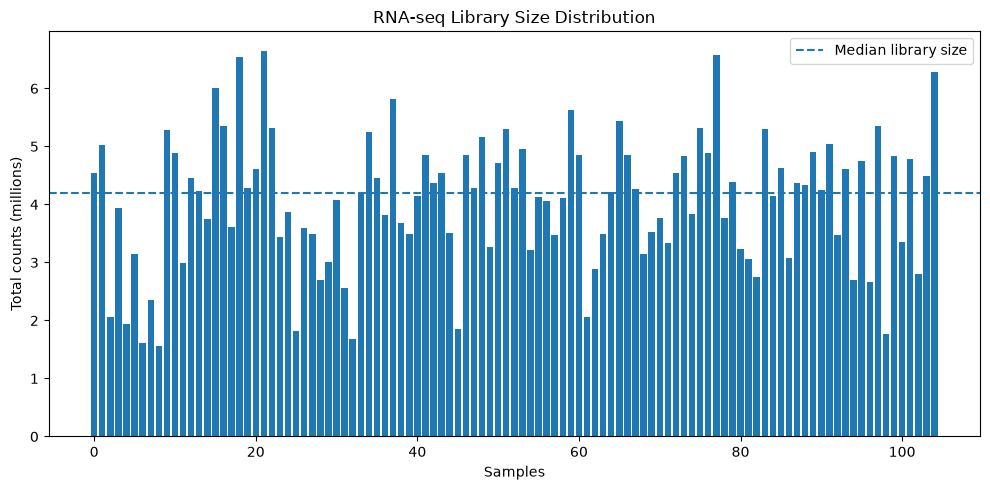

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    range(len(library_sizes)),
    library_sizes.values / 1_000_000
)

plt.axhline(
    library_sizes.median() / 1_000_000,
    linestyle="--",
    label="Median library size"
)

plt.xlabel("Samples")
plt.ylabel("Total counts (millions)")
plt.title("RNA-seq Library Size Distribution")
plt.legend()
plt.tight_layout()
plt.show()

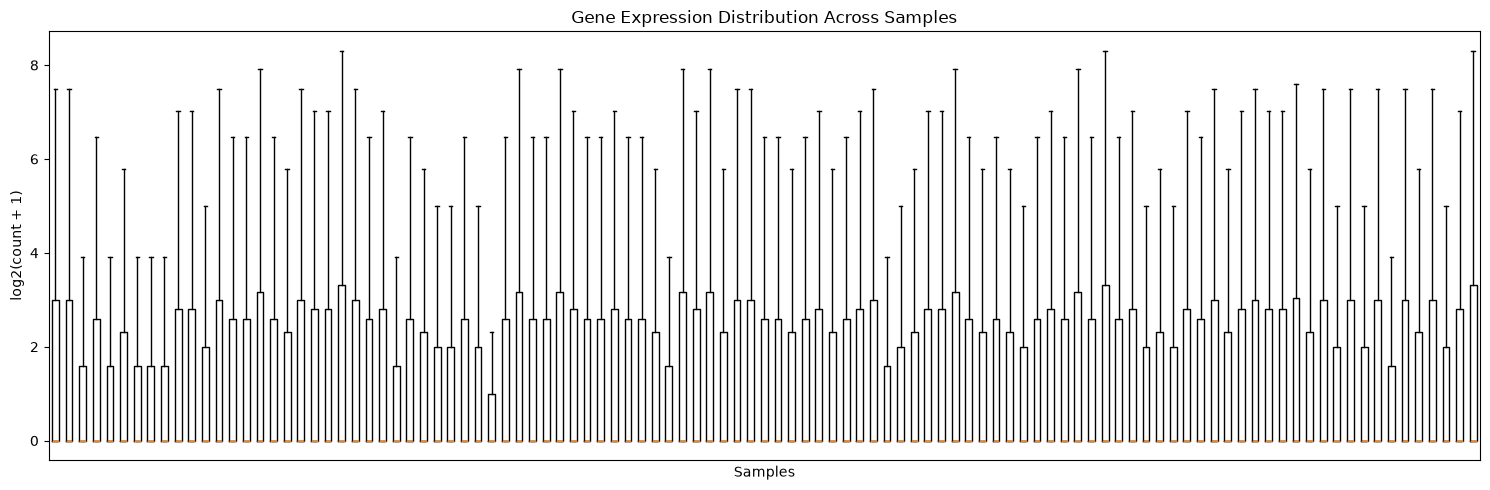

In [27]:
# Log-transform counts for visualization only
log_counts = np.log2(counts.set_index("gene_id") + 1)

# Boxplot for all 105 samples
plt.figure(figsize=(15, 5))

plt.boxplot(
    [log_counts[col].values for col in log_counts.columns],
    showfliers=False
)

plt.xlabel("Samples")
plt.ylabel("log2(count + 1)")
plt.title("Gene Expression Distribution Across Samples")
plt.xticks([])
plt.tight_layout()
plt.show()

In [28]:
# Separate gene IDs from expression counts
expression = counts.set_index("gene_id")

# Number of samples in which each gene has at least 10 counts
gene_detection = (expression >= 10).sum(axis=1)

# Summarize gene detection
print("Total genes:", expression.shape[0])
print("Genes detected in at least 1 sample:", (gene_detection >= 1).sum())
print("Genes detected in at least 10 samples:", (gene_detection >= 10).sum())
print("Genes detected in at least 20 samples:", (gene_detection >= 20).sum())
print("Genes detected in all 105 samples:", (gene_detection == 105).sum())

Total genes: 63140
Genes detected in at least 1 sample: 20283
Genes detected in at least 10 samples: 16897
Genes detected in at least 20 samples: 15775
Genes detected in all 105 samples: 6589


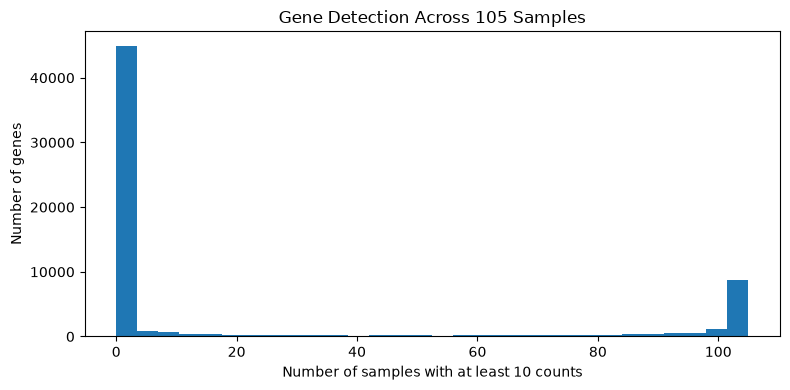

In [29]:
plt.figure(figsize=(8, 4))

plt.hist(gene_detection, bins=30)

plt.xlabel("Number of samples with at least 10 counts")
plt.ylabel("Number of genes")
plt.title("Gene Detection Across 105 Samples")

plt.tight_layout()
plt.show()

In [30]:
# Calculate counts per million
library_sizes = expression.sum(axis=0)

cpm = expression.div(library_sizes, axis=1) * 1_000_000

# Check genes detected at different CPM thresholds
for threshold in [0.5, 1, 2]:
    detected = (cpm >= threshold).sum(axis=1)

    print(
        f"Genes with CPM >= {threshold} "
        f"in at least 17 samples: {(detected >= 17).sum()}"
    )

Genes with CPM >= 0.5 in at least 17 samples: 22110
Genes with CPM >= 1 in at least 17 samples: 19224
Genes with CPM >= 2 in at least 17 samples: 16565


In [31]:
print("Data type:", expression.dtypes.unique())
print("Minimum value:", expression.min().min())
print("Maximum value:", expression.max().max())

print("Are all values integers?",
      np.all(expression.values == np.floor(expression.values)))

print("\nFirst five gene counts:")
display(expression.iloc[:5, :5])

Data type: [dtype('int64')]
Minimum value: 0
Maximum value: 497032
Are all values integers? True

First five gene counts:


,1_VP_001_perilesioneel_huid_A12,1_VP_008_01_X_lesioneel_huid_A1,2_VP_001_gezond_huid_B12,2_VP_008_01_X_perilesioneel_huid_B1,3_VP_002_01_lesioneel__C12
gene_id,,,,,
ENSG00000000003,109,89,13,26,7
ENSG00000000005,50,7,1,1,0
ENSG00000000419,197,193,25,127,50
ENSG00000000457,90,62,26,92,28
ENSG00000000460,14,14,5,16,5


In [32]:
!R --version

R version 4.5.2 (2025-10-31) -- "[Not] Part in a Rumble"
Copyright (C) 2025 The R Foundation for Statistical Computing
Platform: x86_64-pc-linux-gnu

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under the terms of the
GNU General Public License versions 2 or 3.
For more information about these matters see
https://www.gnu.org/licenses/.



In [33]:
!Rscript -e 'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager::install("edgeR", ask=FALSE, update=FALSE)'


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cloud.r-project.org
Bioconductor version 3.22 (BiocManager 1.30.27), R 4.5.2 (2025-10-31)
Installing package(s) 'edgeR'
also installing the dependencies ‘statmod’, ‘limma’, ‘locfit’

trying URL 'https://cloud.r-project.org/src/contrib/statmod_1.5.2.tar.gz'
trying URL 'https://bioconductor.org/packages/3.22/bioc/src/contrib/limma_3.66.0.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/locfit_1.5-9.12.tar.gz'
trying URL 'https://bioconductor.org/packages/3.22/bioc/src/contrib/edgeR_4.8.2.tar.gz'
* installing *source* package ‘statmod’ ...
** this is package ‘statmod’ version ‘1.5.2’
** package ‘statmod’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
sh: 1: make: not found
Error in `<current-expression>` : error in running command
* removing ‘/home/geetankshi/R/x86_64-pc-li

In [34]:
!Rscript -e 'library(edgeR); cat("edgeR version:", as.character(packageVersion("edgeR")), "\n"); cat("Bioconductor version:", as.character(BiocManager::version()), "\n")'

Error in library(edgeR) : there is no package called ‘edgeR’
Execution halted


In [37]:
!which gcc g++ gfortran make

In [38]:
!df -h /

Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p6   49G   42G  5.3G  89% /


In [39]:
!Rscript -e 'ip <- installed.packages(); print(ip[rownames(ip) %in% c("BiocManager","statmod","locfit","limma","edgeR"), c("Package","Version"), drop=FALSE])'

            Package       Version  
BiocManager "BiocManager" "1.30.27"


In [ ]:
!Rscript -e 'install.packages(c("statmod", "locfit"), repos="https://cloud.r-project.org")'

In [ ]:
!Rscript -e 'cat(R.version.string, "\n"); library(edgeR); cat("edgeR version:", as.character(packageVersion("edgeR")), "\n")'

In [ ]:
import subprocess
import shutil

print("Rscript location:", shutil.which("Rscript"))

result = subprocess.run(
    ["Rscript", "--version"],
    capture_output=True,
    text=True
)

print("Output:", result.stdout)
print("Errors:", result.stderr)
print("Return code:", result.returncode)

In [ ]:
result = subprocess.run(
    ["Rscript", "-e", 'library(edgeR); print(packageVersion("edgeR"))'],
    capture_output=True,
    text=True
)

print("Output:", result.stdout)
print("Errors:", result.stderr)
print("Return code:", result.returncode)

In [ ]:
print("JUPYTER IS WORKING")

In [43]:
print("jupyter is working")

jupyter is working


In [44]:
!Rscript --version 

Rscript (R) version 4.6.1 (2026-06-24)


In [45]:
!Rscript -e 'library(edgeR); packageVersion("edgeR")'

Loading required package: limma
[1] ‘4.10.7’


In [46]:
# Save count matrix in compressed format
counts.to_csv(
    "data/processed/GSE311770_counts.tsv.gz",
    sep="\t",
    index=False,
    compression="gzip"
)

# Save metadata in count-matrix sample order
matched_metadata.to_csv(
    "data/processed/GSE311770_matched_metadata.csv"
)

print("Count matrix and metadata saved successfully.")

Count matrix and metadata saved successfully.


In [47]:
# Samples contributed by each patient
patient_groups = pd.crosstab(
    matched_metadata["patient_id"],
    matched_metadata["group"]
)

display(patient_groups.head(12))

print("Total unique patient IDs:", patient_groups.shape[0])

print("\nSamples contributed per tissue group:")
print(matched_metadata["group"].value_counts())

group,Healthy control,Lesional,Non-lesional,Perilesional
patient_id,,,,
"""1-VP-008-01-X",0,1,0,0
"""16-VP-021-01",0,0,0,1
"""17-VP-021-01",0,0,1,0
"""18-VP-024-01",0,1,0,0
"""19-VP-024-01",0,0,0,1
"""2-VP-008-01-X",0,0,0,1
"""20-VP-024-01",0,0,1,0
"""24-VP-013-01",0,0,0,1
"""25-VP-015-01",0,1,0,0


Total unique patient IDs: 76

Samples contributed per tissue group:
group
Perilesional       27
Non-lesional       27
Healthy control    27
Lesional           24
Name: count, dtype: int64


In [48]:
# Count samples contributed by each patient ID
patient_summary = (
    matched_metadata
    .groupby("patient_id")
    .agg(
        sample_count=("group", "size"),
        tissue_groups=("group", lambda x: ", ".join(sorted(set(x))))
    )
    .sort_values("sample_count", ascending=False)
)

print("Unique IDs:", len(patient_summary))

display(patient_summary.head(20))

Unique IDs: 76


,sample_count,tissue_groups
patient_id,,
"""VP-014-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-009-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-007-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-018-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-005-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-004-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-003-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-006-01",3,"Lesional, Non-lesional, Perilesional"
"""VP-002-01",3,"Lesional, Non-lesional, Perilesional"


In [49]:
for patient in sorted(matched_metadata["patient_id"].unique()):
    print(patient)

"1-VP-008-01-X
"16-VP-021-01
"17-VP-021-01
"18-VP-024-01
"19-VP-024-01
"2-VP-008-01-X
"20-VP-024-01
"24-VP-013-01
"25-VP-015-01
"26-VP-015-01
"27-VP-022-01
"28-VP-022-01
"29-VP-022-01
"3-VP-008-01-X
"30-VP-026-01
"31-VP-026-01
"32-VP-026-01
"36-VP-023-01
"37-VP-023-01
"38-VP-023-01
"39-VP-025-01
"4-VP-017-01
"40-VP-025-01
"41-VP-025-01
"42-VP-027-01
"43-VP-027-01
"44-VP-027-01
"5-VP-017-01
"6-VP-017-01
"7-VP-020-01-X
"8-VP-020-01-X
"9-VP-020-01-X
"Control 1
"Control 10
"Control 11
"Control 12
"Control 13
"Control 14
"Control 15
"Control 16
"Control 17
"Control 18
"Control 19
"Control 2
"Control 20
"Control 21
"Control 22
"Control 23
"Control 24
"Control 25
"Control 26
"Control 27
"Control 3
"Control 4
"Control 5
"Control 6
"Control 7
"Control 8
"Control 9
"VP-001
"VP-002-01
"VP-003-01
"VP-004-01
"VP-005-01
"VP-006-01
"VP-007-01
"VP-008_01
"VP-009-01
"VP-010-01
"VP-011-01
"VP-012-01
"VP-014-01
"VP-016-01
"VP-018-01
"VP-019-01
"VP-021-01


In [50]:
import re

def extract_patient_id(title):
    title = str(title).strip().strip('"').strip()

    # Extract vitiligo patient identifier
    vp_match = re.search(
        r'VP[-_]\d{3}(?:[-_]\d{2})?(?:[-_]X)?',
        title,
        flags=re.IGNORECASE
    )

    if vp_match:
        return vp_match.group(0).upper().replace("_", "-")

    # Extract healthy control identifier
    control_match = re.search(
        r'Control[-_ ]*\d+',
        title,
        flags=re.IGNORECASE
    )

    if control_match:
        return control_match.group(0).replace("_", " ").title()

    return "Unknown"

clean_metadata["patient_id"] = (
    clean_metadata["!Sample_title"].apply(extract_patient_id)
)

print("Unique patient IDs:", clean_metadata["patient_id"].nunique())
print("\nPatient ID distribution:")
print(clean_metadata["patient_id"].value_counts().head(15))

KeyError: '!Sample_title'

In [51]:
import re

def extract_patient_id(title):
    title = str(title).strip().strip('"')

    # Extract VP patient identifier
    match = re.search(
        r'VP[-_]\d{3}(?:[-_]\d{2})?',
        title,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(0).upper().replace("_", "-")

    # Extract healthy control identifier
    control = re.search(
        r'Control[-_ ]*(\d+)',
        title,
        flags=re.IGNORECASE
    )

    if control:
        return "Control " + control.group(1)

    return "Unknown"


clean_metadata["patient_id"] = (
    metadata_df["!Sample_title"].apply(extract_patient_id)
)

In [52]:
patient_summary = (
    clean_metadata
    .groupby("patient_id")
    .agg(
        sample_count=("group", "size"),
        tissue_groups=("group", lambda x: ", ".join(sorted(set(x))))
    )
    .sort_values("sample_count", ascending=False)
)

print("Unique IDs:", clean_metadata["patient_id"].nunique())
print("Unknown IDs:", (clean_metadata["patient_id"] == "Unknown").sum())

display(patient_summary)

Unique IDs: 54
Unknown IDs: 0


,sample_count,tissue_groups
patient_id,,
VP-008-01,5,"Lesional, Non-lesional, Perilesional"
VP-020-01,3,"Lesional, Non-lesional, Perilesional"
VP-023-01,3,"Lesional, Non-lesional, Perilesional"
VP-026-01,3,"Lesional, Non-lesional, Perilesional"
VP-025-01,3,"Lesional, Non-lesional, Perilesional"
VP-027-01,3,"Lesional, Non-lesional, Perilesional"
VP-012-01,3,"Lesional, Non-lesional, Perilesional"
VP-014-01,3,"Lesional, Non-lesional, Perilesional"
VP-017-01,3,"Lesional, Non-lesional, Perilesional"


In [53]:
import os

os.makedirs("data/processed", exist_ok=True)

clean_metadata.to_csv(
    "data/processed/GSE311770_final_sample_metadata.csv",
    index=False
)

patient_summary.to_csv(
    "data/processed/GSE311770_patient_summary.csv"
)

print("All metadata saved successfully!")

All metadata saved successfully!


In [54]:
checkpoint = """
VITILIGO TRM RESEARCH - PROGRESS CHECKPOINT

Dataset: GSE311770
Total samples: 105
Total genes: 63,140

Sample groups:
Lesional: 24
Perilesional: 27
Non-lesional: 27
Healthy controls: 27

Completed:
1. Downloaded GEO count matrix and series matrix.
2. Explored gene-count matrix.
3. Checked missing values and duplicate gene IDs.
4. Classified all 105 samples.
5. Matched all 105 samples to GEO metadata.
6. Performed library-size QC.
7. Examined gene-expression distributions.
8. Examined gene detection and CPM thresholds.
9. Installed R 4.6.1 and edgeR 4.10.7.
10. Corrected patient ID extraction.

Current patient IDs: 54
Unknown patient IDs: 0

Next steps:
1. Verify patient identifiers against GEO metadata.
2. Establish paired experimental design.
3. Apply edgeR filtering.
4. Perform TMM normalization.
5. PCA and differential expression.
6. TRM-associated survival and metabolic analysis.

IMPORTANT:
No differential expression analysis has been performed yet.
"""

with open("documentation/progress_checkpoint.txt", "w") as file:
    file.write(checkpoint)

print("Research checkpoint saved!")

Research checkpoint saved!


In [55]:
import os

print(os.getcwd())

/home/geetankshi/vitiligo_TRM_research


In [56]:
!ls -lh *.ipynb

-rw-rw-r-- 1 geetankshi geetankshi 618 Oct 31 00:51 Untitled.ipynb


In [57]:
!ls -lh data/processed/

total 3.1M
-rw-rw-r-- 1 geetankshi geetankshi 3.1M Oct 31 01:32 GSE311770_counts.tsv.gz
-rw-rw-r-- 1 geetankshi geetankshi 6.7K Oct 31 01:54 GSE311770_final_sample_metadata.csv
-rw-rw-r-- 1 geetankshi geetankshi 7.2K Oct 31 01:32 GSE311770_matched_metadata.csv
-rw-rw-r-- 1 geetankshi geetankshi 2.1K Oct 31 01:54 GSE311770_patient_summary.csv
-rw-rw-r-- 1 geetankshi geetankshi 7.2K Oct 30 23:55 GSE311770_sample_metadata.csv


In [58]:
!ls -lh notebooks/

total 0


In [59]:
!find . -name "01_GEO_Dataset_Exploration.ipynb"

./data/01_GEO_Dataset_Exploration.ipynb


In [1]:
import pandas as pd
import numpy as np

# Reload count matrix
counts = pd.read_csv(
    "data/processed/GSE311770_counts.tsv.gz",
    sep="\t",
    compression="gzip"
)

# Reload corrected metadata
clean_metadata = pd.read_csv(
    "data/processed/GSE311770_final_sample_metadata.csv"
)

# Restore sample matching
matched_metadata = (
    clean_metadata
    .set_index("library_name")
    .reindex(counts.columns[1:])
)

# Restore expression matrix
expression = counts.set_index("gene_id")

print("Count matrix:", counts.shape)
print("Metadata:", clean_metadata.shape)
print("Matched samples:", matched_metadata["group"].notna().sum())
print("Unique patient IDs:", clean_metadata["patient_id"].nunique())

FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/GSE311770_counts.tsv.gz'

In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nDoes the processed data folder exist?")
print(os.path.exists("data/processed"))

print("\nFiles in current directory:")
print(os.listdir())

Current working directory:
/home/geetankshi/vitiligo_TRM_research/data

Does the processed data folder exist?
False

Files in current directory:
['raw', 'processed', '.ipynb_checkpoints']


In [3]:
import os

os.chdir("/home/geetankshi/vitiligo_TRM_research")

print("Working directory:", os.getcwd())
print("Processed folder exists:", os.path.exists("data/processed"))

Working directory: /home/geetankshi/vitiligo_TRM_research
Processed folder exists: True


In [4]:
import pandas as pd
import numpy as np

counts = pd.read_csv(
    "data/processed/GSE311770_counts.tsv.gz",
    sep="\t",
    compression="gzip"
)

clean_metadata = pd.read_csv(
    "data/processed/GSE311770_final_sample_metadata.csv"
)

matched_metadata = (
    clean_metadata
    .set_index("library_name")
    .reindex(counts.columns[1:])
)

expression = counts.set_index("gene_id")

print("Count matrix:", counts.shape)
print("Metadata:", clean_metadata.shape)
print("Matched samples:", matched_metadata["group"].notna().sum())
print("Unique patient IDs:", clean_metadata["patient_id"].nunique())

Count matrix: (63140, 106)
Metadata: (105, 4)
Matched samples: 105
Unique patient IDs: 54


In [5]:
print("Unique patient IDs:")
print(sorted(clean_metadata["patient_id"].unique()))

print("\nSamples per patient:")
print(
    clean_metadata.groupby("patient_id")
    .size()
    .value_counts()
    .sort_index()
)

Unique patient IDs:
['Control 1', 'Control 10', 'Control 11', 'Control 12', 'Control 13', 'Control 14', 'Control 15', 'Control 16', 'Control 17', 'Control 18', 'Control 19', 'Control 2', 'Control 20', 'Control 21', 'Control 22', 'Control 23', 'Control 24', 'Control 25', 'Control 26', 'Control 27', 'Control 3', 'Control 4', 'Control 5', 'Control 6', 'Control 7', 'Control 8', 'Control 9', 'VP-001', 'VP-002-01', 'VP-003-01', 'VP-004-01', 'VP-005-01', 'VP-006-01', 'VP-007-01', 'VP-008-01', 'VP-009-01', 'VP-010-01', 'VP-011-01', 'VP-012-01', 'VP-013-01', 'VP-014-01', 'VP-015-01', 'VP-016-01', 'VP-017-01', 'VP-018-01', 'VP-019-01', 'VP-020-01', 'VP-021-01', 'VP-022-01', 'VP-023-01', 'VP-024-01', 'VP-025-01', 'VP-026-01', 'VP-027-01']

Samples per patient:
1    28
2     3
3    22
5     1
Name: count, dtype: int64


In [6]:
print(
    clean_metadata[
        ["library_name", "group", "patient_id"]
    ].sort_values(["patient_id", "group"]).to_string(index=False)
)

                       library_name           group patient_id
                   44_Control_1__D7 Healthy control  Control 1
                  10_controle_10_B2 Healthy control Control 10
                  11_controle_11_C2 Healthy control Control 11
                  12_controle_12_D2 Healthy control Control 12
                  21_Controle_13_E3 Healthy control Control 13
                  22_Controle_14_F3 Healthy control Control 14
           23_Controle_15_gezond_G3 Healthy control Control 15
                   33_Control_16_A5 Healthy control Control 16
                   34_Control_17_B5 Healthy control Control 17
                   35_Control_18_C5 Healthy control Control 18
                   45_Control_19_E6 Healthy control Control 19
                   45_Control_2__E7 Healthy control  Control 2
                   46_Control_20_F6 Healthy control Control 20
                   47_Control_21_G6 Healthy control Control 21
                   48_Control_22_H6 Healthy control Con

In [7]:
# Number of unique patients in each group
print("Unique patients per group:")
print(clean_metadata.groupby("group")["patient_id"].nunique())

# Number of samples contributed by each patient
samples_per_patient = (
    clean_metadata.groupby(["group", "patient_id"])
    .size()
    .reset_index(name="samples")
)

print("\nSample counts per group:")
print(samples_per_patient.groupby(["group", "samples"]).size())

# Show only patients with multiple samples
print("\nPatients with multiple samples:")
print(samples_per_patient[samples_per_patient["samples"] > 1].to_string(index=False))

Unique patients per group:
group
Healthy control    27
Lesional           24
Non-lesional       26
Perilesional       26
Name: patient_id, dtype: int64

Sample counts per group:
group            samples
Healthy control  1          27
Lesional         1          24
Non-lesional     1          25
                 2           1
Perilesional     1          25
                 2           1
dtype: int64

Patients with multiple samples:
       group patient_id  samples
Non-lesional  VP-008-01        2
Perilesional  VP-008-01        2


In [8]:
clean_metadata.loc[
    clean_metadata["patient_id"] == "VP-008-01",
    ["library_name", "group", "patient_id"]
]

,library_name,group,patient_id
55,13_VP_008_01_perilesioneel_huid_E2,Perilesional,VP-008-01
56,14_VP_008_01_gezond_F2,Non-lesional,VP-008-01
62,1_VP_008_01_X_lesioneel_huid_A1,Lesional,VP-008-01
73,2_VP_008_01_X_perilesioneel_huid_B1,Perilesional,VP-008-01
84,3_VP_008_01_X_gezond_huid_C1,Non-lesional,VP-008-01


In [9]:
print(
    "Unique vitiligo patients:",
    clean_metadata.loc[
        clean_metadata["group"] != "Healthy control",
        "patient_id"
    ].nunique()
)

Unique vitiligo patients: 27


In [10]:
vp008 = clean_metadata[
    clean_metadata["patient_id"] == "VP-008-01"
]["library_name"]

for library in vp008:
    row = metadata_df[
        metadata_df["!Sample_description"].str.contains(
            library, regex=False, na=False
        )
    ]

    print(row[
        ["!Sample_geo_accession", "!Sample_title", "!Sample_description"]
    ].to_string(index=False))
    print("-" * 50)

NameError: name 'metadata_df' is not defined

In [11]:
import gzip

metadata_file = "data/raw/GSE311770_series_matrix.txt.gz"

with gzip.open(metadata_file, "rt") as f:
    lines = f.readlines()

metadata = {}

for line in lines:
    if line.startswith("!Sample_"):
        key, value = line.rstrip("\n").split("\t", 1)
        metadata.setdefault(key, []).append(value.strip('"'))

metadata_df = pd.DataFrame(metadata)

print("Metadata restored:", metadata_df.shape)

ValueError: All arrays must be of the same length

In [12]:
import gzip
import pandas as pd

metadata_file = "data/raw/GSE311770_series_matrix.txt.gz"

geo_metadata = {}

with gzip.open(metadata_file, "rt") as f:
    for line in f:
        if line.startswith("!Sample_geo_accession") or \
           line.startswith("!Sample_title") or \
           line.startswith("!Sample_description"):

            key, value = line.rstrip("\n").split("\t", 1)

            geo_metadata[key] = value.split("\t")

metadata_df = pd.DataFrame({
    key: values
    for key, values in geo_metadata.items()
})

print("Metadata shape:", metadata_df.shape)
print(metadata_df.head(2))

Metadata shape: (105, 3)
                        !Sample_title !Sample_geo_accession  \
0  "VP-001, perilesional skin biopsy"          "GSM9331734"   
1       "VP-001, healthy skin biopsy"          "GSM9331735"   

                               !Sample_description  
0  "Library name: 1_VP_001_perilesioneel_huid_A12"  
1         "Library name: 2_VP_001_gezond_huid_B12"  


In [13]:
vp008 = clean_metadata[
    clean_metadata["patient_id"] == "VP-008-01"
]["library_name"]

for library in vp008:
    row = metadata_df[
        metadata_df["!Sample_description"].str.contains(
            library, regex=False, na=False
        )
    ]

    print(row[
        ["!Sample_geo_accession", "!Sample_title", "!Sample_description"]
    ].to_string(index=False))

    print("-" * 40)

!Sample_geo_accession                         !Sample_title                                !Sample_description
         "GSM9331789" "VP-008_01, perilesional skin biopsy" "Library name: 13_VP_008_01_perilesioneel_huid_E2"
----------------------------------------
!Sample_geo_accession                    !Sample_title                    !Sample_description
         "GSM9331790" "VP-008_01, healthy skin biopsy" "Library name: 14_VP_008_01_gezond_F2"
----------------------------------------
!Sample_geo_accession                         !Sample_title                             !Sample_description
         "GSM9331796" "1-VP-008-01-X, lesional skin biopsy" "Library name: 1_VP_008_01_X_lesioneel_huid_A1"
----------------------------------------
!Sample_geo_accession                             !Sample_title                                 !Sample_description
         "GSM9331807" "2-VP-008-01-X, perilesional skin biopsy" "Library name: 2_VP_008_01_X_perilesioneel_huid_B1"
-------------------

In [14]:
print(
    metadata_df[
        metadata_df["!Sample_geo_accession"].str.contains(
            "GSM9331789|GSM9331790|GSM9331796|GSM9331807|GSM9331818",
            regex=True,
            na=False
        )
    ][
        ["!Sample_geo_accession", "!Sample_title", "!Sample_description"]
    ].to_string(index=False)
)

!Sample_geo_accession                             !Sample_title                                 !Sample_description
         "GSM9331789"     "VP-008_01, perilesional skin biopsy"  "Library name: 13_VP_008_01_perilesioneel_huid_E2"
         "GSM9331790"          "VP-008_01, healthy skin biopsy"              "Library name: 14_VP_008_01_gezond_F2"
         "GSM9331796"     "1-VP-008-01-X, lesional skin biopsy"     "Library name: 1_VP_008_01_X_lesioneel_huid_A1"
         "GSM9331807" "2-VP-008-01-X, perilesional skin biopsy" "Library name: 2_VP_008_01_X_perilesioneel_huid_B1"
         "GSM9331818"      "3-VP-008-01-X, healthy skin biopsy"        "Library name: 3_VP_008_01_X_gezond_huid_C1"


In [15]:
print("Data types:")
print(expression.dtypes.value_counts())

print("\nExample count values:")
print(expression.iloc[:10, :5])

print("\nAre all values integers?")
print(np.all(expression.values == np.floor(expression.values)))

print("\nAre any values negative?")
print((expression.values < 0).any())

Data types:
int64    105
Name: count, dtype: int64

Example count values:
                 1_VP_001_perilesioneel_huid_A12  \
gene_id                                            
ENSG00000000003                              109   
ENSG00000000005                               50   
ENSG00000000419                              197   
ENSG00000000457                               90   
ENSG00000000460                               14   
ENSG00000000938                               14   
ENSG00000000971                             1051   
ENSG00000001036                               15   
ENSG00000001084                              279   
ENSG00000001167                               43   

                 1_VP_008_01_X_lesioneel_huid_A1  2_VP_001_gezond_huid_B12  \
gene_id                                                                      
ENSG00000000003                               89                        13   
ENSG00000000005                                7                   

In [16]:
print(counts.head(5).to_string(index=False))

print("\nCount matrix summary:")
print(expression.describe().loc[["min", "50%", "mean", "max"]])

        gene_id  1_VP_001_perilesioneel_huid_A12  1_VP_008_01_X_lesioneel_huid_A1  2_VP_001_gezond_huid_B12  2_VP_008_01_X_perilesioneel_huid_B1  3_VP_002_01_lesioneel__C12  3_VP_008_01_X_gezond_huid_C1  4_VP_002_01_perilesioneel__D12  4_VP_017_01_lesioneel_D1  5_VP_002_01_gezond_E12  5_VP_017_01_perilesioneel_E1  6_VP_003_01_lesioneel_F12  6_VP_017_01_gezond_F1  7_VP_003_01_perilesioneel_G12  7_VP_020_01_X_lesioneel_G1  8_VP_003_01_gezond_H12  8_VP_020_01_X_perilesioneel_H1  9_VP_004_01_lesioneel_A11  9_VP_020_01_X_gezond_A2  10_VP_004_01_perilesioneel_B11  10_controle_10_B2  11_VP_004_01_gezond_C11  11_controle_11_C2  12_VP_005_01_lesioneel_D11  12_controle_12_D2  13_VP_005_01_perilesioneel_E11  13_VP_008_01_perilesioneel_huid_E2  14_VP_005_01_gezond_F11  14_VP_008_01_gezond_F2  15_VP_006_01_lesioneel_G11  15_VP_021_01_lesioneel_G2  16_VP_006_01_perilesioneel_H11  16_VP_021_01_perilesioneel_H2  17_VP_006_01_gezond_A10  17_VP_021_01_gezond_A3  18_VP_007_01_lesioneel_B10  18_VP_024_01_

In [17]:
print("First 5 gene IDs:")
print(counts["gene_id"].head().to_list())

print("\nFirst 5 sample columns:")
print(counts.columns[1:6].to_list())

print("\nFirst 5 genes, first 5 samples:")
print(expression.iloc[:5, :5].to_string())

print("\nCount summary:")
print(expression.describe().loc[["min", "50%", "mean", "max"]].round(2))

First 5 gene IDs:
['ENSG00000000003', 'ENSG00000000005', 'ENSG00000000419', 'ENSG00000000457', 'ENSG00000000460']

First 5 sample columns:
['1_VP_001_perilesioneel_huid_A12', '1_VP_008_01_X_lesioneel_huid_A1', '2_VP_001_gezond_huid_B12', '2_VP_008_01_X_perilesioneel_huid_B1', '3_VP_002_01_lesioneel__C12']

First 5 genes, first 5 samples:
                 1_VP_001_perilesioneel_huid_A12  1_VP_008_01_X_lesioneel_huid_A1  2_VP_001_gezond_huid_B12  2_VP_008_01_X_perilesioneel_huid_B1  3_VP_002_01_lesioneel__C12
gene_id                                                                                                                                                                     
ENSG00000000003                              109                               89                        13                                   26                           7
ENSG00000000005                               50                                7                         1                                  

In [18]:
print("Matrix dimensions:", expression.shape)

print("\nFirst 10 count values:")
print(expression.iloc[:2, :5].values)

print("\nMinimum count:", expression.values.min())
print("Maximum count:", expression.values.max())
print("Mean count:", round(expression.values.mean(), 2))
print("Median count:", expression.values.median())

Matrix dimensions: (63140, 105)

First 10 count values:
[[109  89  13  26   7]
 [ 50   7   1   1   0]]

Minimum count: 0
Maximum count: 497032
Mean count: 64.06


AttributeError: 'numpy.ndarray' object has no attribute 'median'

In [19]:
print("Median count:", np.median(expression.values))

Median count: 0.0


In [1]:
import gzip

metadata_file = "data/raw/GSE311770_series_matrix.txt.gz"

keywords = [
    "activity", "active", "stable",
    "vdas", "vdis", "mvida",
    "treatment", "clinical"
]

print("Clinical information in GEO metadata:\n")

with gzip.open(metadata_file, "rt") as f:
    for line in f:
        if line.startswith("!Sample_"):
            if any(word in line.lower() for word in keywords):
                print(line[:1200])

Clinical information in GEO metadata:



FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/GSE311770_series_matrix.txt.gz'

In [2]:
from pathlib import Path

project = Path.home() / "vitiligo_TRM_research"

print("Project exists:", project.exists())
print("\nFiles matching series_matrix:")

for file in project.rglob("*series_matrix*"):
    print(file)

Project exists: True

Files matching series_matrix:
/home/geetankshi/vitiligo_TRM_research/data/raw/GSE311770_series_matrix.txt.gz


In [3]:
metadata_file = str(
    project / "data/raw/GSE311770_series_matrix.txt.gz"
)

In [4]:
import gzip

keywords = [
    "activity", "active", "stable",
    "vdas", "vdis", "mvida",
    "treatment", "clinical"
]

with gzip.open(metadata_file, "rt") as f:
    for line in f:
        if line.startswith("!Sample_"):
            if any(word in line.lower() for word in keywords):
                print(line[:1200])

!Sample_extract_protocol_ch1	"The sampled tissue was lysed mechanically using a 1000 µL pipette tip, followed by shearing through a syringe (Terumo Corporation, Tokyo, Japan) fitted with a 20Gx1½ needle (Terumo Corporation). Total RNA was extracted using the conventional TriReagent/chloroform method and subsequently purified with the Direct-zol Microprep RNA Kit (Zymo Research), including on-column DNase I treatment, according to the manufacturer’s instructions. As residual genomic DNA was detected in some samples, an additional DNase treatment was performed using the TURBO DNA-free™ Kit (Invitrogen, Thermo Fisher Scientific) on all RNA extracts."	"The sampled tissue was lysed mechanically using a 1000 µL pipette tip, followed by shearing through a syringe (Terumo Corporation, Tokyo, Japan) fitted with a 20Gx1½ needle (Terumo Corporation). Total RNA was extracted using the conventional TriReagent/chloroform method and subsequently purified with the Direct-zol Microprep RNA Kit (Zymo Re

In [6]:
import gzip

metadata_file = (
    "/home/geetankshi/vitiligo_TRM_research/"
    "data/raw/GSE311770_series_matrix.txt.gz"
)

keywords = [
    "activity", "active", "stable", "vdas",
    "vdis", "mvida", "disease status",
    "clinical status", "progression"
]

with gzip.open(metadata_file, "rt") as f:
    for line in f:
        if line.startswith("!Sample_"):
            lower = line.lower()

            # Only inspect potentially relevant sample-level fields
            if any(field in lower for field in [
                "characteristics", "description", "title"
            ]):
                if any(word in lower for word in keywords):
                    print(line[:2000])